Loading Dataset...

First 5 Feature Rows:
   radius1  texture1  perimeter1   area1  smoothness1  compactness1  \
0    17.99     10.38      122.80  1001.0      0.11840       0.27760   
1    20.57     17.77      132.90  1326.0      0.08474       0.07864   
2    19.69     21.25      130.00  1203.0      0.10960       0.15990   
3    11.42     20.38       77.58   386.1      0.14250       0.28390   
4    20.29     14.34      135.10  1297.0      0.10030       0.13280   

   concavity1  concave_points1  symmetry1  fractal_dimension1  ...  radius3  \
0      0.3001          0.14710     0.2419             0.07871  ...    25.38   
1      0.0869          0.07017     0.1812             0.05667  ...    24.99   
2      0.1974          0.12790     0.2069             0.05999  ...    23.57   
3      0.2414          0.10520     0.2597             0.09744  ...    14.91   
4      0.1980          0.10430     0.1809             0.05883  ...    22.54   

   texture3  perimeter3   area3  smoothness3  compactnes

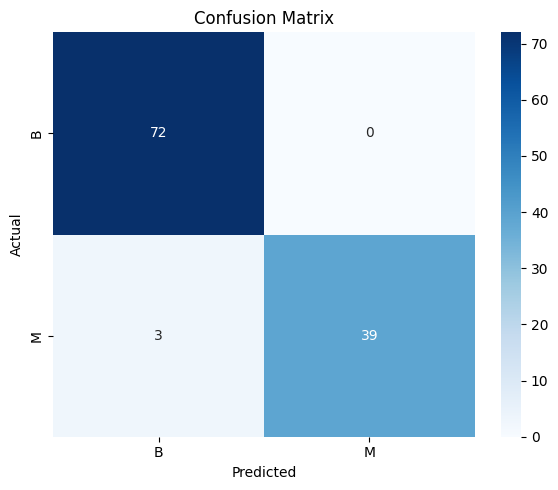


Top 10 Important Features:
            Feature  Importance
23            area3    0.151412
27  concave_points3    0.126497
20          radius3    0.093475
22       perimeter3    0.083642
7   concave_points1    0.081082
2        perimeter1    0.077126
0           radius1    0.061990
6        concavity1    0.050818
3             area1    0.045916
26       concavity3    0.030022


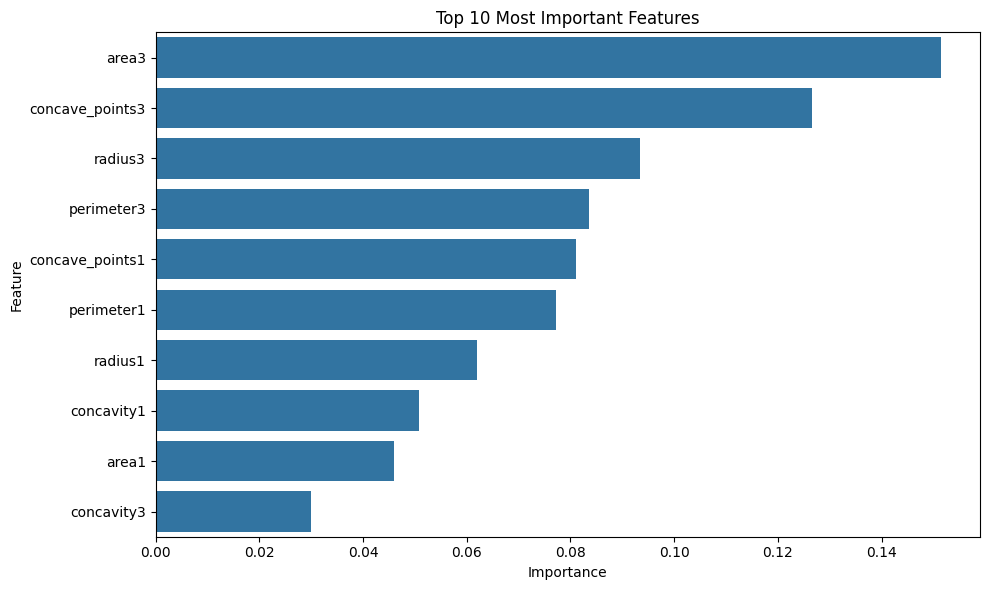


Conclusion

1. Dataset was downloaded from UCI Machine Learning Repository.
2. Missing values were handled using Median Imputation.
3. Features were standardized using StandardScaler.
4. Random Forest Classifier was trained on the processed data.
5. Model performance was evaluated using:
   - Accuracy
   - Precision
   - Recall
   - F1 Score
   - Confusion Matrix
6. Feature importance analysis identified the most influential predictors.

The model achieves high classification performance and can
effectively distinguish between benign and malignant tumors.



In [4]:
!pip install ucimlrepo -q

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 50)
print("Loading Dataset...")
print("=" * 50)

breast_cancer = fetch_ucirepo(id=17)

X = breast_cancer.data.features
y = breast_cancer.data.targets

print("\nFirst 5 Feature Rows:")
print(X.head())

print("\nFirst 5 Target Rows:")
print(y.head())

# ============================================================
# 3. Dataset Information
# ============================================================

print("\n" + "=" * 50)
print("Dataset Information")
print("=" * 50)

print("Feature Shape:", X.shape)
print("Target Shape :", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nMissing Values:")
print(X.isnull().sum())

print("\nData Types:")
print(X.dtypes)

# ============================================================
# 4. Check Duplicate Records
# ============================================================

print("\n" + "=" * 50)
print("Checking Duplicate Records")
print("=" * 50)

duplicate_rows = X.duplicated().sum()

print("Duplicate Rows:", duplicate_rows)

if duplicate_rows > 0:
    X = X.drop_duplicates()
    print("Duplicates Removed")

# ============================================================
# 5. Encode Target Variable
# ============================================================

print("\n" + "=" * 50)
print("Encoding Target Variable")
print("=" * 50)

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y.values.ravel())

print("Target Classes:")
print(label_encoder.classes_)

print("Encoded Values:")
print(np.unique(y))

# ============================================================
# 6. Identify Numerical Features
# ============================================================

numeric_features = X.select_dtypes(include=np.number).columns

print("\nNumeric Features Count:", len(numeric_features))

# ============================================================
# 7. Preprocessing Pipeline
# ============================================================

# Missing Value Handling
# Feature Scaling

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features)
    ]
)

# ============================================================
# 8. Train-Test Split
# ============================================================

print("\n" + "=" * 50)
print("Splitting Data")
print("=" * 50)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples :", X_test.shape[0])

# ============================================================
# 9. Build Complete ML Pipeline
# ============================================================

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier",
         RandomForestClassifier(
             n_estimators=100,
             random_state=42
         ))
    ]
)

# ============================================================
# 10. Train Model
# ============================================================

print("\n" + "=" * 50)
print("Training Random Forest Model")
print("=" * 50)

model.fit(X_train, y_train)

print("Training Complete!")

# ============================================================
# 11. Make Predictions
# ============================================================

y_pred = model.predict(X_test)

# ============================================================
# 12. Model Evaluation
# ============================================================

print("\n" + "=" * 50)
print("Model Evaluation")
print("=" * 50)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

# ============================================================
# 13. Classification Report
# ============================================================

print("\n" + "=" * 50)
print("Classification Report")
print("=" * 50)

print(classification_report(y_test, y_pred))

# ============================================================
# 14. Confusion Matrix
# ============================================================

print("\n" + "=" * 50)
print("Confusion Matrix")
print("=" * 50)

cm = confusion_matrix(y_test, y_pred)

print(cm)

# ============================================================
# 15. Visualize Confusion Matrix
# ============================================================

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

# ============================================================
# 16. Feature Importance
# ============================================================

classifier = model.named_steps["classifier"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 10 Important Features:")

print(feature_importance.head(10))

# ============================================================
# 17. Plot Feature Importance
# ============================================================

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Most Important Features")
plt.tight_layout()
plt.show()

# ============================================================
# 18. Final Conclusion
# ============================================================

print("\n" + "=" * 50)
print("Conclusion")
print("=" * 50)

print("""
1. Dataset was downloaded from UCI Machine Learning Repository.
2. Missing values were handled using Median Imputation.
3. Features were standardized using StandardScaler.
4. Random Forest Classifier was trained on the processed data.
5. Model performance was evaluated using:
   - Accuracy
   - Precision
   - Recall
   - F1 Score
   - Confusion Matrix
6. Feature importance analysis identified the most influential predictors.

The model achieves high classification performance and can
effectively distinguish between benign and malignant tumors.
""")